# Implicit Variational Inference on a Banana Distribution

Learn a sampler for a curved, two-dimensional distribution using:

1. **Gaussian VI:** an explicit baseline with a known density.
2. **Adversarial DRE:** an implicit generator and a density-ratio classifier.
3. **SIVI:** the bonus method, using a mixture of explicit Gaussian conditionals.

The banana density is a synthetic posterior; there is no dataset.
Run all cells in order on CPU. Requires PyTorch, NumPy, and Matplotlib.


## 1. Setup

Use a fixed seed and 3,000 updates per method. DRE makes five classifier
updates per generator update. Its smaller generator learning rate helps the
classifier track the changing sampler. `K=24` controls SIVI's auxiliary
mixture components.


In [1]:
import math
import time
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

SEED, STEPS, BATCH = 7, 3000, 512
D_STEPS, K, WIDTH, NOISE_DIM = 5, 24, 64, 4
LR_G, LR_D, LR_VI = 2e-4, 1e-3, 1e-3
BETAS, REF_STD = (0.5, 0.9), 3.0
S1, S2, LOG2PI = 1.0, 0.3, math.log(2 * math.pi)

def seed_all(seed):
    torch.manual_seed(seed)
    np.random.seed(seed)

torch.set_num_threads(2)
torch.set_default_dtype(torch.float32)
seed_all(SEED)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})


## 2. The banana target

The target prefers points near the curve $z_2=z_1^2$:

$$\log\widetilde p(z)=-\frac{z_1^2}{2}
-\frac{(z_2-z_1^2)^2}{2(0.3)^2}.$$

The tilde means unnormalized; training needs only this log-density.
Exact samples, $z_1=u$ and $z_2=u^2+0.3v$ with independent normal noise,
are used **only for evaluation**.

DRE uses the known reference $r=\mathcal N(0,9I_2)$, where $I_2$ is the
identity matrix. This reference supplies classifier examples and is different
from the target. Its sample scale and log-density must agree.


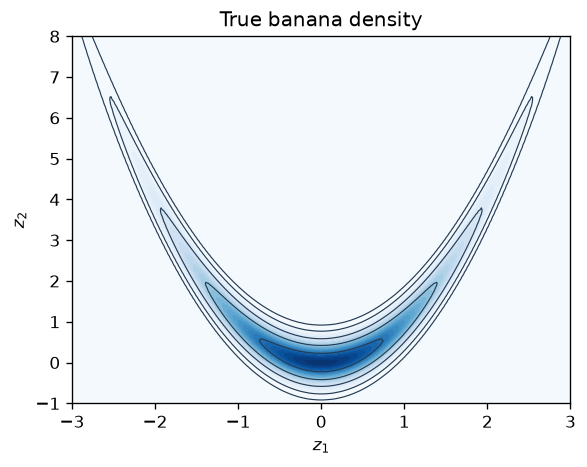

In [2]:
def log_target(z):
    x, y = z.unbind(-1)
    return -0.5 * (x / S1).square() - 0.5 * ((y - x.square()) / S2).square()

def log_reference(z):
    return -0.5 * (z / REF_STD).square().sum(-1) - LOG2PI - 2 * math.log(REF_STD)

def target_sample(n):
    uv = torch.randn(n, 2)  # Evaluation only.
    x = S1 * uv[:, 0]
    return torch.stack((x, x.square() + S2 * uv[:, 1]), -1)

xx, yy = np.meshgrid(np.linspace(-3, 3, 180, dtype=np.float32),
                     np.linspace(-1, 8, 200, dtype=np.float32))
grid = torch.from_numpy(np.stack((xx, yy), -1))
density = (log_target(grid) - math.log(2 * math.pi * S1 * S2)).exp().numpy()

def contours(ax, title):
    ax.contour(xx, yy, density, levels=[0.005, 0.02, 0.08, 0.2, 0.4],
               colors='#243b53', linewidths=0.7)
    ax.set(title=title, xlabel='$z_1$', ylabel='$z_2$', xlim=(-3, 3), ylim=(-1, 8))

fig, ax = plt.subplots(figsize=(5, 4))
ax.contourf(xx, yy, density, levels=30, cmap='Blues')
contours(ax, 'True banana density')
plt.tight_layout()
plt.show()


## 3. What VI optimizes

For an approximation $q_\phi$, maximize the evidence lower bound (ELBO):

$$\mathcal L=\mathbb E_q[\log\widetilde p(z)-\log q_\phi(z)]
=\mathbb E_q[\log\widetilde p(z)]+H(q_\phi).$$

The first term rewards likely target regions; entropy $H(q)$ rewards spread.
Maximizing this is equivalent to minimizing $\mathrm{KL}(q\Vert p)$.
Without entropy, the sampler could concentrate at a high-density point.
For an implicit neural sampler, **$\log q_\phi(z)$ is the intractable term**.


## 4. Explicit Gaussian baseline

Use $z=\mu+L\epsilon$, with $\epsilon\sim\mathcal N(0,I_2)$ and covariance
$LL^\top$. A positive diagonal keeps the covariance valid. PyTorch provides
analytic Gaussian entropy, and `rsample()` lets gradients flow through
samples. A full-covariance Gaussian can rotate and stretch an ellipse,
but cannot bend it along the banana.


In [3]:
class GaussianVI(nn.Module):
    def __init__(self):
        super().__init__()
        self.mu = nn.Parameter(torch.zeros(2))
        self.raw_diag = nn.Parameter(torch.zeros(2))
        self.offdiag = nn.Parameter(torch.zeros(()))

    def distribution(self):
        d = F.softplus(self.raw_diag) + 1e-4
        L = torch.stack((torch.stack((d[0], torch.zeros_like(d[0]))),
                         torch.stack((self.offdiag, d[1]))))
        return torch.distributions.MultivariateNormal(self.mu, scale_tril=L)

    def sample(self, n):
        return self.distribution().rsample((n,))

def gaussian_loss(model, n):
    q = model.distribution()
    return -log_target(q.rsample((n,))).mean() - q.entropy()


Minimize the negative ELBO with Adam. This ordinary training loop will also
be used for SIVI, which has a single differentiable objective.


In [4]:
def fit(model, loss_function):
    optimizer = torch.optim.Adam(model.parameters(), lr=LR_VI, betas=BETAS)
    started = time.perf_counter()
    for _ in range(STEPS):
        loss = loss_function(model, BATCH)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return time.perf_counter() - started

seed_all(SEED)
gaussian = GaussianVI()
gaussian_seconds = fit(gaussian, gaussian_loss)
print(f'Gaussian trained in {gaussian_seconds:.1f} s')


Gaussian trained in 4.9 s


## 5. Implicit generator and density-ratio classifier

The generator `G` maps normal noise into two-dimensional samples. The
classifier `D` returns a raw logit $T(z)$. Train it with equal numbers of
generator samples (label 1) and reference samples (label 0).

At the ideal logistic optimum:

$$P(1\mid z)=\frac{q(z)}{q(z)+r(z)},\qquad
T^*(z)=\log\frac{q(z)}{r(z)}.$$

Thus **$\log q(z)\approx T(z)+\log r(z)$**, supplying the missing ELBO term.
The classifier never sees true banana samples. `softplus` implements a
numerically stable logistic loss; no output sigmoid is needed.


In [5]:
def mlp(input_dim, output_dim):
    return nn.Sequential(nn.Linear(input_dim, WIDTH), nn.Tanh(),
                         nn.Linear(WIDTH, WIDTH), nn.Tanh(),
                         nn.Linear(WIDTH, output_dim))

def draw(G, n):
    return G(torch.randn(n, NOISE_DIM))

def discriminator_loss(D, z_q, z_r):
    return F.softplus(-D(z_q)).mean() + F.softplus(D(z_r)).mean()


## 6. Alternating DRE optimization

Alternate five classifier updates with one generator update minimizing:

$$J_G=\mathbb E[T(G(\epsilon))+\log r(G(\epsilon))
-\log\widetilde p(G(\epsilon))].$$

Detach generator samples while training `D`. While training `G`, freeze
`D`'s weights **but keep gradients through its input**. At the ideal ratio,
this gives the entropy gradient: the omitted explicit parameter-score term
has expectation zero under smoothness and differentiation assumptions.

An imperfect classifier makes this an ELBO proxy. If `G` moves too quickly,
`D` can lag and give misleading gradients, causing oscillation or poor coverage.
Classifier accuracy of 50% is not the goal: `D` compares $q$ with $r$, not $p$.


In [6]:
def train_dre(steps=STEPS, k=D_STEPS, lr_g=LR_G):
    seed_all(SEED)
    G, D = mlp(NOISE_DIM, 2), mlp(2, 1)
    opt_g = torch.optim.Adam(G.parameters(), lr=lr_g, betas=BETAS)
    opt_d = torch.optim.Adam(D.parameters(), lr=LR_D, betas=BETAS)
    plot_noise = torch.randn(1000, NOISE_DIM, generator=torch.Generator().manual_seed(SEED + 1))
    with torch.no_grad():
        snapshots = {0: G(plot_noise).numpy()}
    started = time.perf_counter()
    for step in range(steps):
        for _ in range(k):
            z_q = draw(G, BATCH).detach()  # D must not update G.
            z_r = REF_STD * torch.randn(BATCH, 2)
            loss_d = discriminator_loss(D, z_q, z_r)
            opt_d.zero_grad()
            loss_d.backward()
            opt_d.step()

        D.requires_grad_(False)  # Freeze weights, retain input gradients.
        z = draw(G, BATCH)
        loss_g = (D(z).squeeze(-1) + log_reference(z) - log_target(z)).mean()
        opt_g.zero_grad()
        loss_g.backward()
        opt_g.step()
        D.requires_grad_(True)
        if step + 1 in (steps // 2, steps):
            with torch.no_grad():
                snapshots[step + 1] = G(plot_noise).numpy()
    return G, D, snapshots, time.perf_counter() - started


### DRE samples during training

Show the generator before training, after 1,500 updates, and after 3,000 updates.
Each panel uses the same noise inputs and target contours, so the changing
sample cloud shows how the generator learns the banana's curve.


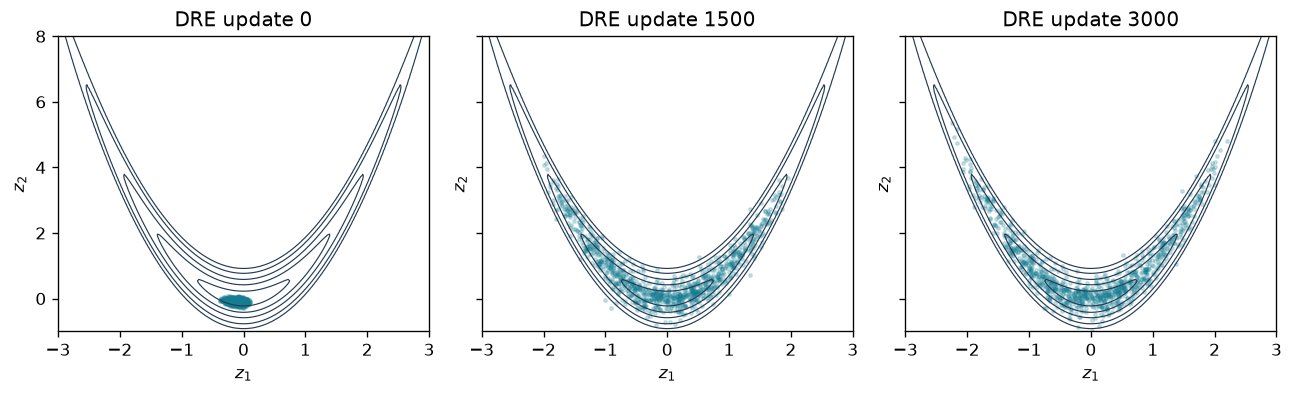

DRE trained in 43.2 s


In [7]:
G, D, snapshots, dre_seconds = train_dre()
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharex=True, sharey=True)
for ax, (step, z) in zip(axes, snapshots.items()):
    ax.scatter(*z.T, s=4, alpha=0.2, color='#147d92')
    contours(ax, f'DRE update {step}')
plt.tight_layout()
plt.show()
print(f'DRE trained in {dre_seconds:.1f} s')


## 7. Bonus: SIVI

Generate a random mean $\psi=g_\phi(\epsilon)$, then sample from the explicit
conditional $q(z\mid\psi)=\mathcal N(\psi,\sigma^2 I_2)$. Its marginal density
is still unknown, but each conditional density can be evaluated.

Sample $z$ from mean $\psi_0$ and include $K=24$ independent auxiliary means:

$$\mathcal L_K=\mathbb E\left[\log\widetilde p(z)-\log\left(
\frac1{K+1}\sum_{j=0}^Kq(z\mid\psi_j)\right)\right]\leq\mathcal L.$$

**Include the mean that generated $z$.** This is a lower surrogate in
expectation; increasing $K$ tightens it under regularity assumptions but costs
more. SIVI needs no discriminator. The independent auxiliary pool is shared
across the batch, preserving each sample's expected objective while correlating
the estimates. Keep gradients through the means, scale, and samples.


In [8]:
class SIVI(nn.Module):
    def __init__(self):
        super().__init__()
        self.means = mlp(NOISE_DIM, 2)
        self.raw_sigma = nn.Parameter(torch.tensor(-1.17))

    @property
    def sigma(self):
        return 0.03 + F.softplus(self.raw_sigma)

    def sample(self, n):
        return draw(self.means, n) + self.sigma * torch.randn(n, 2)

def conditional_log_q(z, mean, sigma):
    return -0.5 * ((z - mean) / sigma).square().sum(-1) - 2 * sigma.log() - LOG2PI

def sivi_loss(model, n):
    own, aux = draw(model.means, n), draw(model.means, K)
    sigma = model.sigma
    z = own + sigma * torch.randn_like(own)
    own_log_q = conditional_log_q(z, own, sigma)
    aux_log_q = conditional_log_q(z[:, None, :], aux[None, :, :], sigma)
    log_terms = torch.cat((own_log_q[:, None], aux_log_q), dim=1)
    log_mix = torch.logsumexp(log_terms, dim=1) - math.log(K + 1)
    return (log_mix - log_target(z)).mean()


Fit SIVI by minimizing $-\mathcal L_K$ with the same Adam loop as the Gaussian.
All methods use the same number of VI updates; their computation costs differ.


In [9]:
seed_all(SEED)
sivi = SIVI()
sivi_seconds = fit(sivi, sivi_loss)
print(f'SIVI trained in {sivi_seconds:.1f} s')


SIVI trained in 10.9 s


## 8. Compare the results

Compare fresh samples using squared maximum mean discrepancy (**MMD²**),
with Gaussian similarity $k(a,b)=\exp(-\|a-b\|^2/2)$ and bandwidth 1.
Lower means better sample agreement at this bandwidth. This finite-sample
estimate includes self-pairs. Target samples are used only here for evaluation.

The plot shows geometry that a single score can miss. These tuned,
single-seed results are a demonstration, not a universal ranking.


Method      MMD squared   Training s
Gaussian         0.1375          4.9
DRE              0.0011         43.2
SIVI             0.0230         10.9


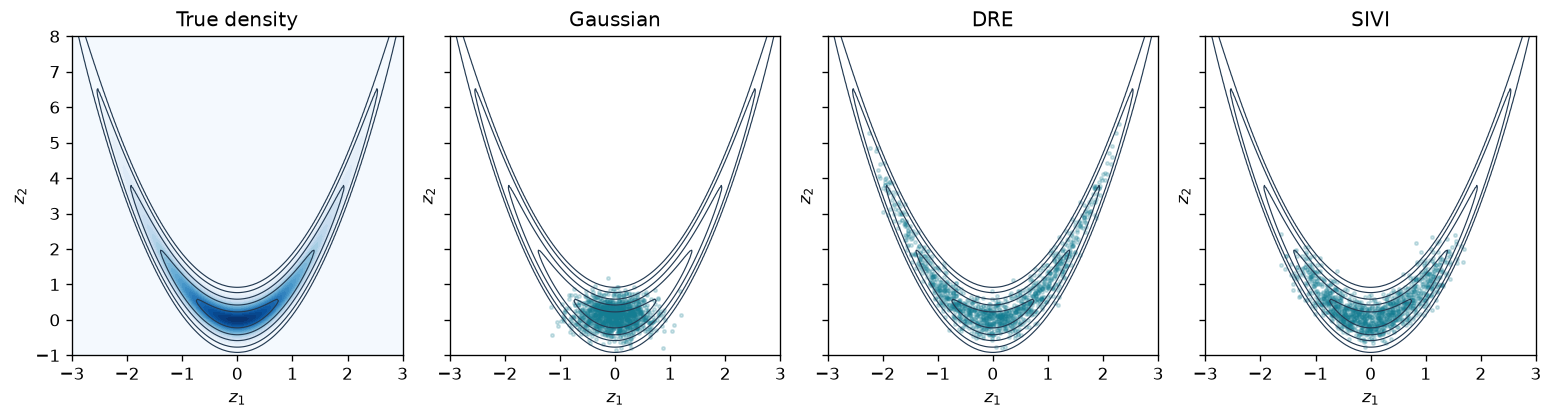

In [10]:
def mmd2(a, b):
    def kernel(x, y):
        return torch.exp(-torch.cdist(x, y).square() / 2)
    return (kernel(a, a).mean() + kernel(b, b).mean() - 2 * kernel(a, b).mean()).item()

seed_all(SEED + 100)
with torch.no_grad():
    samples = {'Gaussian': gaussian.sample(20000), 'DRE': draw(G, 20000),
               'SIVI': sivi.sample(20000)}
    truth = target_sample(1200)
times = [gaussian_seconds, dre_seconds, sivi_seconds]
results = []
print(f"{'Method':10} {'MMD squared':>12} {'Training s':>12}")
for (name, z), seconds in zip(samples.items(), times):
    score = mmd2(z[:1200], truth)
    results.append(dict(method=name, mmd2=score, seconds=seconds))
    print(f'{name:10} {score:12.4f} {seconds:12.1f}')

fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharex=True, sharey=True)
axes[0].contourf(xx, yy, density, levels=30, cmap='Blues')
contours(axes[0], 'True density')
for ax, (name, z) in zip(axes[1:], samples.items()):
    ax.scatter(*z[:1200].numpy().T, s=4, alpha=0.2, color='#147d92')
    contours(ax, name)
plt.tight_layout()
plt.show()


## 9. Main trade-offs

| Method | Handling the density term | Trade-off |
|---|---|---|
| Gaussian VI | Analytic entropy | Fast and tractable; limited to an ellipse |
| Adversarial DRE | Classifier estimates log(q/r), then add log r | Flexible; classifier error biases updates and training can oscillate |
| SIVI | Explicit conditional densities in a mixture bound | Avoids the classifier; finite-K gap and more computation for larger K |

The Gaussian objective is an ELBO estimate, DRE uses an approximate proxy,
and SIVI optimizes a lower surrogate in expectation. Their values do not have
identical meanings. A small MMD does not prove a perfect fit; interpret it
together with the sample plots.

References: [VI review](https://arxiv.org/abs/1601.00670),
[Adversarial Variational Bayes](https://arxiv.org/abs/1701.04722),
[Semi-Implicit Variational Inference](https://arxiv.org/abs/1805.11183).
